In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = Path("../data/processed/forecast_test_results_v2.csv")

results = pd.read_csv(
    RESULTS_PATH,
    parse_dates=["Datetime"]
)

results = results.dropna(
    subset=["Datetime", "PJME_MW", "Forecast"]
).sort_values("Datetime").reset_index(drop=True)

print("Dataset shape:", results.shape)
display(results.head())

Dataset shape: (29039, 4)


,Datetime,PJME_MW,Forecast,Baseline_Prediction
0,2015-04-10 23:00:00,27327.0,27153.967070,29187.0
1,2015-04-11 00:00:00,25390.0,25082.833318,27327.0
2,2015-04-11 01:00:00,23728.0,23545.637144,25390.0
3,2015-04-11 02:00:00,22743.0,22486.595219,23728.0
4,2015-04-11 03:00:00,22276.0,21971.834294,22743.0


In [2]:
results["Residual"] = results["PJME_MW"] - results["Forecast"]

results["Absolute_Error"] = results["Residual"].abs()

results["Percentage_Error"] = (
    results["Absolute_Error"] /
    results["PJME_MW"].abs().clip(lower=1)
) * 100

display(
    results[
        ["Datetime", "PJME_MW", "Forecast",
         "Residual", "Absolute_Error", "Percentage_Error"]
    ].head(10)
)

,Datetime,PJME_MW,Forecast,Residual,Absolute_Error,Percentage_Error
0,2015-04-10 23:00:00,27327.0,27153.967070,173.032930,173.032930,0.633194
1,2015-04-11 00:00:00,25390.0,25082.833318,307.166682,307.166682,1.209794
2,2015-04-11 01:00:00,23728.0,23545.637144,182.362856,182.362856,0.768556
3,2015-04-11 02:00:00,22743.0,22486.595219,256.404781,256.404781,1.127401
4,2015-04-11 03:00:00,22276.0,21971.834294,304.165706,304.165706,1.365441
5,2015-04-11 04:00:00,22029.0,21933.841974,95.158026,95.158026,0.431967
6,2015-04-11 05:00:00,22248.0,22178.478556,69.521444,69.521444,0.312484
7,2015-04-11 06:00:00,23000.0,22988.426370,11.573630,11.573630,0.050320
8,2015-04-11 07:00:00,24053.0,24000.486752,52.513248,52.513248,0.218323
9,2015-04-11 08:00:00,25079.0,25512.548306,-433.548306,433.548306,1.728730


In [3]:
WINDOW = 24  # 24 hourly observations

results["Rolling_MAE_24h"] = (
    results["Absolute_Error"]
    .rolling(window=WINDOW, min_periods=WINDOW)
    .mean()
)

display(
    results[
        ["Datetime", "Absolute_Error", "Rolling_MAE_24h"]
    ].tail(10)
)

,Datetime,Absolute_Error,Rolling_MAE_24h
29029,2018-08-02 15:00:00,70.466598,269.534972
29030,2018-08-02 16:00:00,747.994203,269.123480
29031,2018-08-02 17:00:00,509.559607,274.894349
29032,2018-08-02 18:00:00,291.395809,260.972840
29033,2018-08-02 19:00:00,266.877249,248.452564
29034,2018-08-02 20:00:00,37.603987,234.005147
29035,2018-08-02 21:00:00,123.416325,227.955010
29036,2018-08-02 22:00:00,372.727081,227.087132
29037,2018-08-02 23:00:00,21.895914,220.468010
29038,2018-08-03 00:00:00,357.031718,231.762965


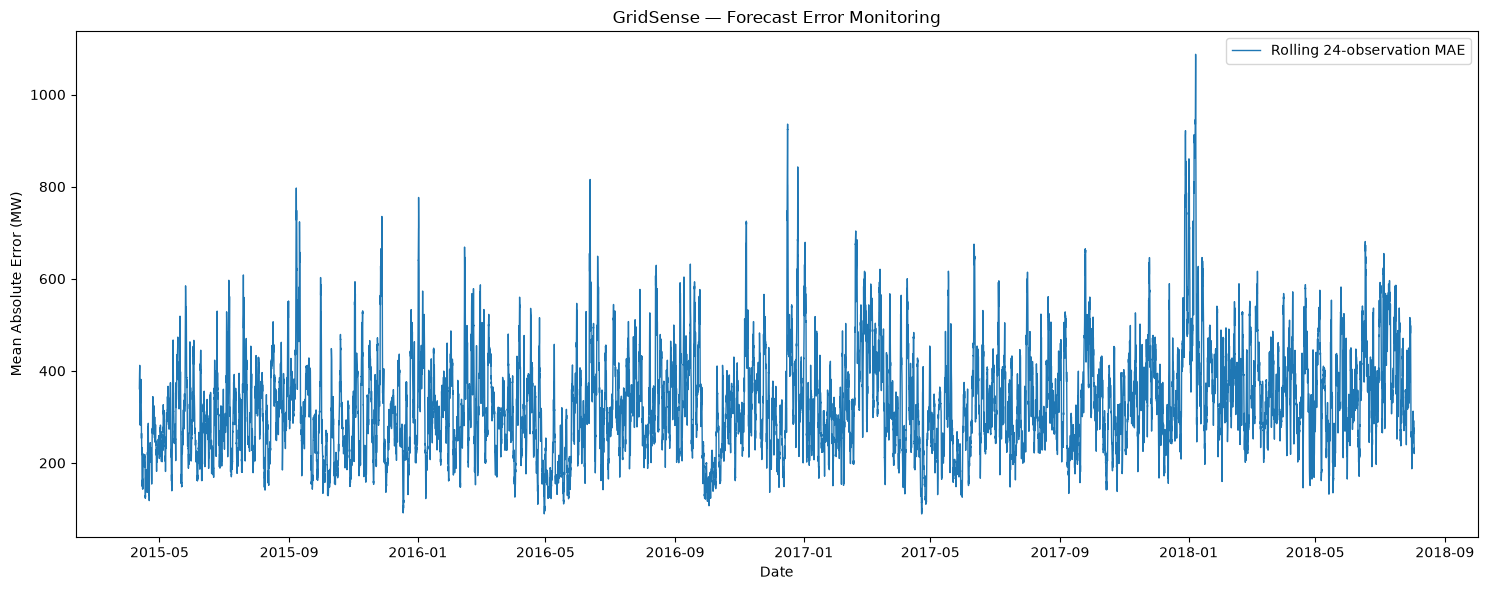

In [4]:
plt.figure(figsize=(15, 6))

plt.plot(
    results["Datetime"],
    results["Rolling_MAE_24h"],
    linewidth=1,
    label="Rolling 24-observation MAE"
)

plt.title("GridSense — Forecast Error Monitoring")
plt.xlabel("Date")
plt.ylabel("Mean Absolute Error (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
monitoring = results.dropna(
    subset=["Rolling_MAE_24h"]
).copy()

# Use the first 20% of available monitoring observations
calibration_size = max(1, int(len(monitoring) * 0.20))

calibration = monitoring.iloc[:calibration_size]
baseline_mae = calibration["Rolling_MAE_24h"].median()
baseline_mad = (
    calibration["Rolling_MAE_24h"] - baseline_mae
).abs().median()

# Robust threshold; floor prevents a zero-spread threshold
threshold = baseline_mae + 3 * 1.4826 * baseline_mad

monitoring["Alert"] = (
    monitoring["Rolling_MAE_24h"] > threshold
)

monitoring["Status"] = np.where(
    monitoring["Alert"],
    "WARNING",
    "NORMAL"
)

print(f"Baseline rolling MAE: {baseline_mae:.2f} MW")
print(f"Warning threshold: {threshold:.2f} MW")
print("Warning observations:", int(monitoring["Alert"].sum()))
print("Total monitored observations:", len(monitoring))

Baseline rolling MAE: 288.10 MW
Warning threshold: 577.48 MW
Warning observations: 774
Total monitored observations: 29016


In [6]:
alert_history = monitoring.loc[
    monitoring["Alert"],
    ["Datetime", "PJME_MW", "Forecast",
     "Absolute_Error", "Rolling_MAE_24h", "Status"]
].copy()

display(alert_history.head(10))

print("Total alert records:", len(alert_history))

,Datetime,PJME_MW,Forecast,Absolute_Error,Rolling_MAE_24h,Status
1075,2015-05-25 18:00:00,35367.0,34730.955204,636.044796,584.610516,WARNING
1076,2015-05-25 19:00:00,35012.0,35153.025754,141.025754,579.729954,WARNING
2058,2015-07-05 17:00:00,37835.0,37184.996991,650.003009,586.516083,WARNING
2059,2015-07-05 18:00:00,38438.0,37954.658423,483.341577,596.707651,WARNING
2060,2015-07-05 19:00:00,37993.0,37801.859153,191.140847,580.725152,WARNING
2389,2015-07-19 12:00:00,43996.0,42835.527330,1160.472670,590.285083,WARNING
2390,2015-07-19 13:00:00,46317.0,45525.615985,791.384015,608.265776,WARNING
2391,2015-07-19 14:00:00,47951.0,47718.660814,232.339186,607.071054,WARNING
3587,2015-09-07 10:00:00,30150.0,29166.566093,983.433907,587.465182,WARNING
3588,2015-09-07 11:00:00,33089.0,31349.514279,1739.485721,640.518309,WARNING


Total alert records: 774


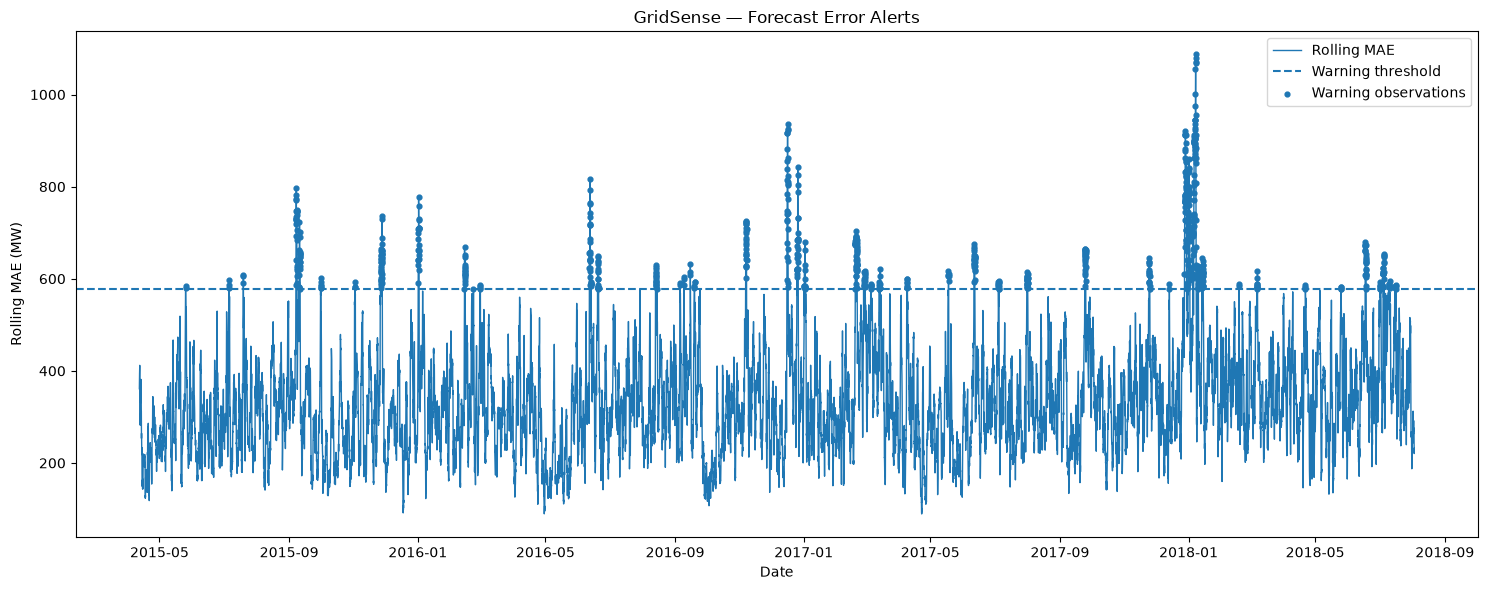

In [7]:
plt.figure(figsize=(15, 6))

plt.plot(
    monitoring["Datetime"],
    monitoring["Rolling_MAE_24h"],
    label="Rolling MAE",
    linewidth=1
)

plt.axhline(
    threshold,
    linestyle="--",
    label="Warning threshold"
)

alert_points = monitoring[monitoring["Alert"]]

plt.scatter(
    alert_points["Datetime"],
    alert_points["Rolling_MAE_24h"],
    label="Warning observations",
    s=12
)

plt.title("GridSense — Forecast Error Alerts")
plt.xlabel("Date")
plt.ylabel("Rolling MAE (MW)")
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
from pathlib import Path

OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

monitoring.to_csv(
    OUTPUT_DIR / "monitoring_results.csv",
    index=False
)

alert_history.to_csv(
    OUTPUT_DIR / "alert_history.csv",
    index=False
)

print("Saved monitoring_results.csv")
print("Saved alert_history.csv")

Saved monitoring_results.csv
Saved alert_history.csv
